Офлайн-пересчёт промежуточной накопленной контрольной точки 250 задач из сохранённых разборов и аудитов. Новых агентов и сети нет; изменение исходных хешей останавливает пересчёт.

In [1]:
import sys
from pathlib import Path
from IPython.display import display, Image, Markdown
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/fipi_checkpoint250.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
import fipi_checkpoint250 as cp
data = cp.collect()
assert data['input_digest'] == 'bdd0c939fedc6b833843e565b6c90e856f8b2185d2a8d52547c80611f746d89a', 'Saved inputs changed: use the code version recorded for this snapshot'
summary, tables = cp.metrics(data)
checks = cp.self_checks(data)
report_path = root / 'data/annotation/analyses/2026-11-09-fipi-checkpoint-250-v1'
if not report_path.exists():
    report_path = report_path.with_name(report_path.name + '.building')
checks


Frozen bytes verified, including archived paths.


{'eda100_summary_reproduced': True,
 'eda100_frequencies_reproduced': True,
 'eda150_node_frequencies_reproduced': True,
 'eda150_included_tasks': 148,
 'eda200_summary_reproduced': True,
 'eda200_frequencies_reproduced': True}

In [2]:
lines = ['| Слой | Отобрано | В частотах | Подтверждённых узлов | Единичные |', '|---|---:|---:|---:|---:|']
for key, name in cp.POPULATIONS.items():
    s = summary[key]
    lines.append(f"| {name} | {s['selected_n']} | {s['included_n']} | {s['confirmed_catalog_nodes']} | {s['singleton_nodes']['numerator']} |")
display(Markdown('\n'.join(lines)))


| Слой | Отобрано | В частотах | Подтверждённых узлов | Единичные |
|---|---:|---:|---:|---:|
| Исходные 50: редакторские связи | 50 | 49 | 136 | 101 |
| Первые 50 новых (запуск 2026-11-02): агентный аудит | 50 | 49 | 48 | 30 |
| Бронь #2, 100 задач (партии 5–12): агентный аудит | 100 | 100 | 65 | 34 |
| Бронь #2, партия 5: Opus, уровень рассуждений по умолчанию | 15 | 15 | 24 | 19 |
| Бронь #2, партии 6–12: Opus, effort low | 85 | 85 | 54 | 29 |
| Бронь #4, первые 50 задач (партии 1–4): Opus, effort low | 50 | 50 | 40 | 27 |
| Все новые 200: агентный аудит | 200 | 199 | 86 | 28 |
| Смешанный накопленный корпус 250 | 250 | 248 | 139 | 49 |

In [3]:
{k: summary[k]['audit_statuses'] for k in ('ext_new50', 'team100', 'team_b6_12_low', 'next50')}

{'ext_new50': {'match': {'numerator': 87, 'denominator': 199},
  'new_candidate': {'numerator': 62, 'denominator': 199},
  'needs_split': {'numerator': 41, 'denominator': 199},
  'uncertain': {'numerator': 9, 'denominator': 199}},
 'team100': {'match': {'numerator': 142, 'denominator': 374},
  'new_candidate': {'numerator': 141, 'denominator': 374},
  'needs_split': {'numerator': 70, 'denominator': 374},
  'uncertain': {'numerator': 21, 'denominator': 374}},
 'team_b6_12_low': {'match': {'numerator': 113, 'denominator': 299},
  'new_candidate': {'numerator': 110, 'denominator': 299},
  'needs_split': {'numerator': 59, 'denominator': 299},
  'uncertain': {'numerator': 17, 'denominator': 299}},
 'next50': {'match': {'numerator': 59, 'denominator': 190},
  'new_candidate': {'numerator': 84, 'denominator': 190},
  'needs_split': {'numerator': 29, 'denominator': 190},
  'uncertain': {'numerator': 18, 'denominator': 190}}}

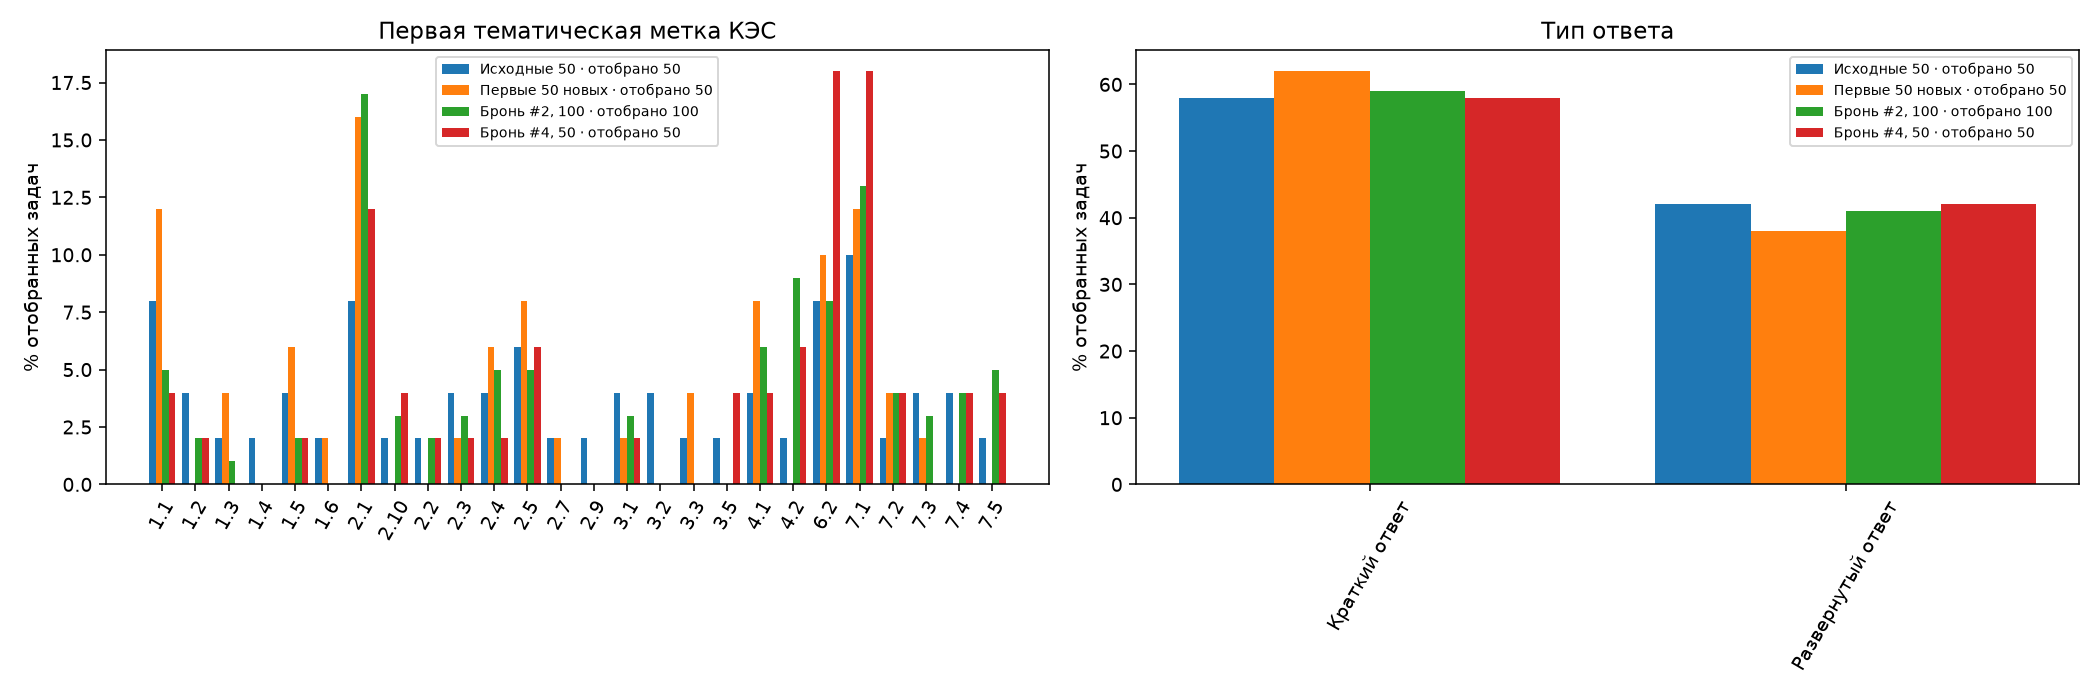

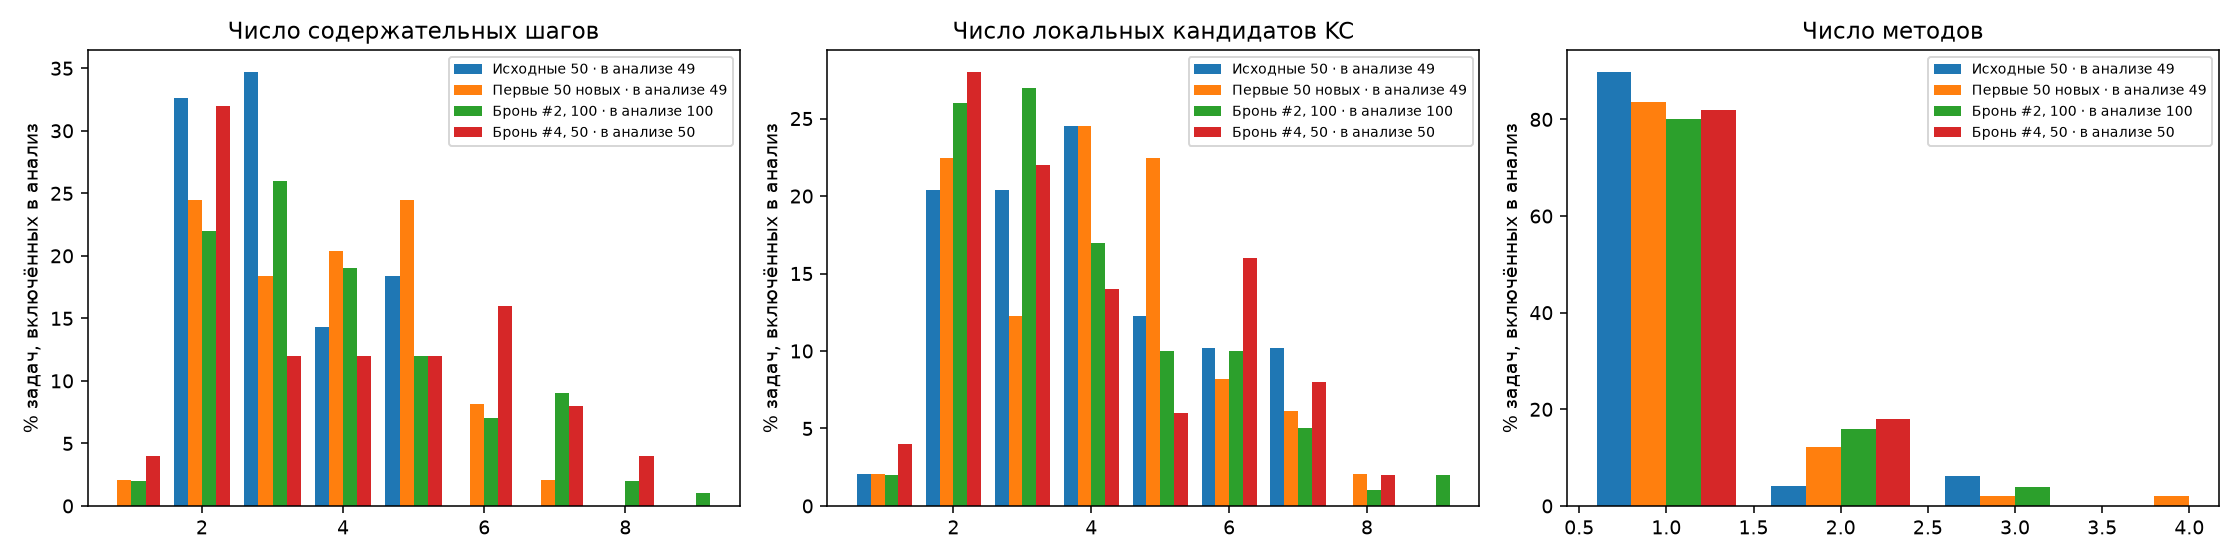

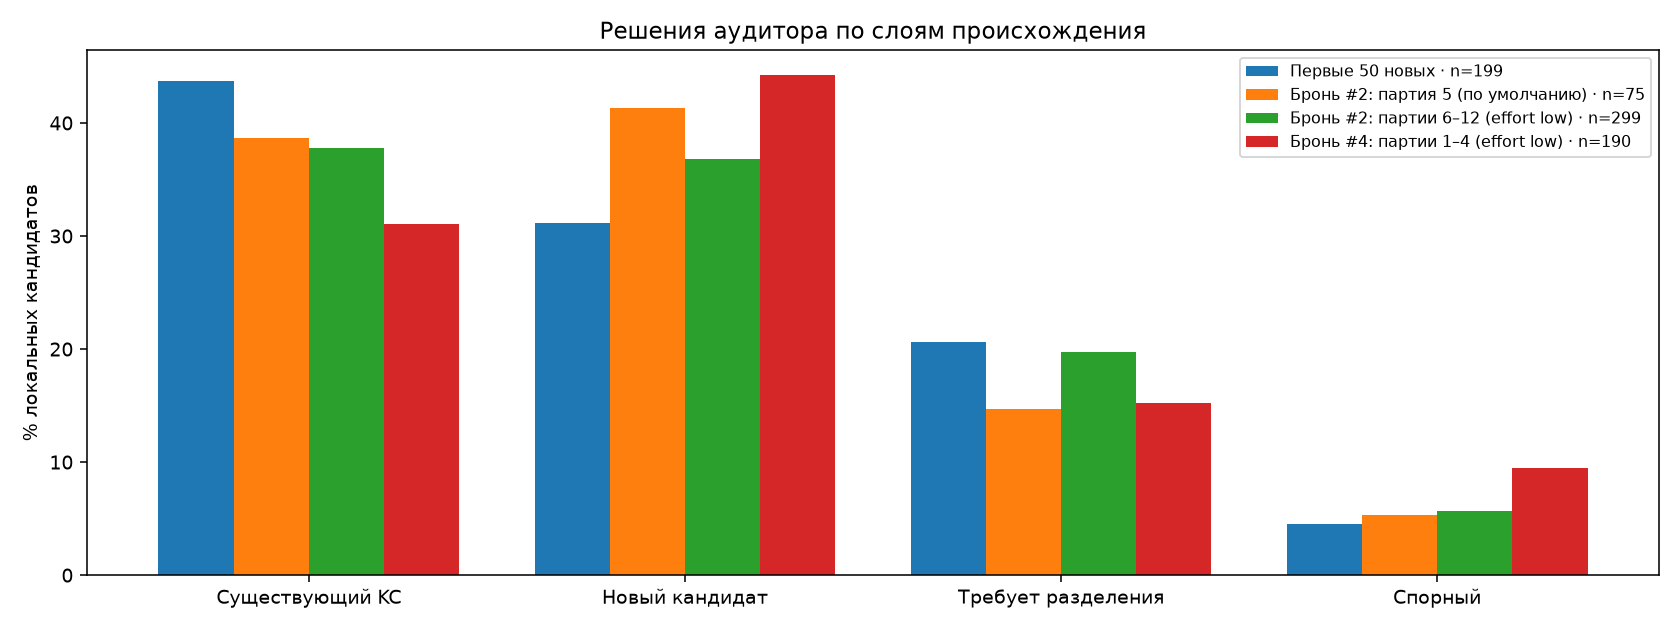

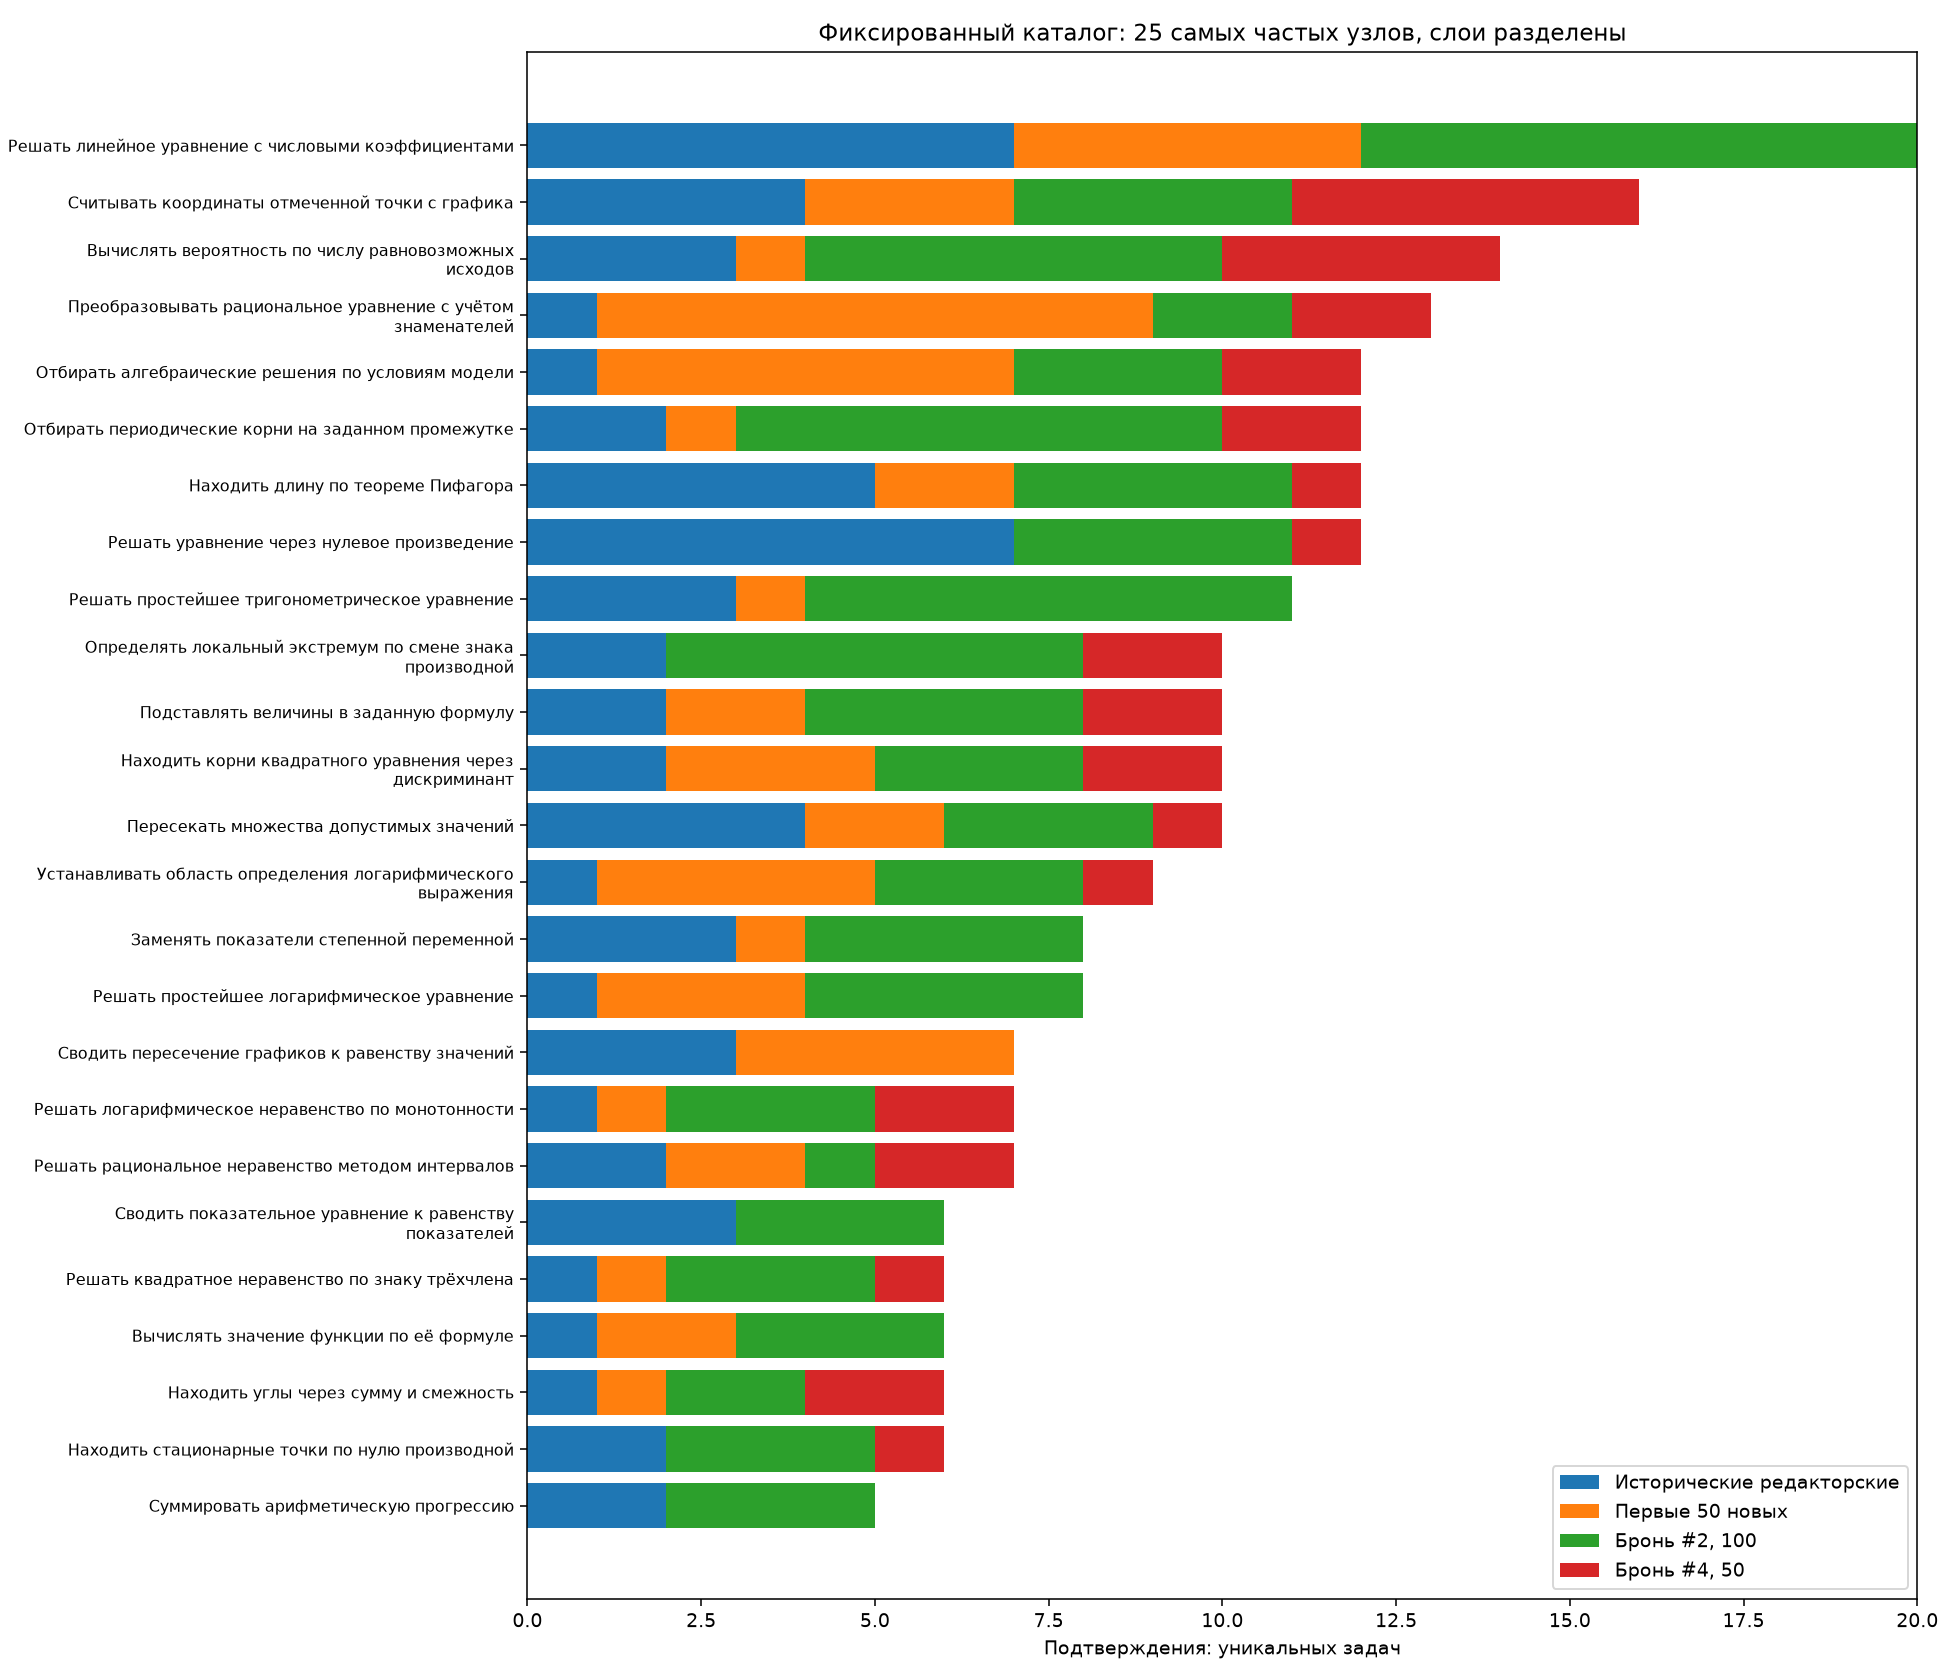

In [4]:
for name in ['01-composition', '02-structure', '03-audit-statuses', '04-catalog-evidence']:
    display(Image(filename=str(report_path / 'figures' / (name + '.png'))))
